# C30 · Tham số Claude

Mục tiêu: fit RF và XGBoost bằng một bộ tham số cố định, chấm trên cùng giờ validation.

Luồng: hourly_unfilled.csv → tách thời gian → C30 đủ history → học điền thiếu từ train → fit toàn bộ cohort train → validation → lưu kết quả.

Đây là thí nghiệm bổ sung sau khi đã xem validation, không phải đánh giá độc lập cuối cùng. Không sử dụng test. Ensemble lấy trung bình RF/XGBoost 50/50, không tối ưu trọng số trên validation.

## 1. Khởi tạo
Tìm gốc dự án để notebook chạy được từ thư mục hiện tại hoặc từ gốc. Dùng lại các hàm tạo đặc trưng và tiền xử lý của FE; seed cố định là 42.

In [1]:
from pathlib import Path
import sys, json, hashlib, platform, time
import numpy as np
import pandas as pd
import sklearn, xgboost
import matplotlib.pyplot as plt
from threadpoolctl import threadpool_limits
from IPython.display import Markdown, display
project_root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p/'data/preprocessed/hourly_unfilled.csv').is_file())
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))
from src import feature_experiments as fe
from src.features import CONFIG_C, add_time_features, add_weather_features, add_history_features, has_history
from src.model import make_cv_model
from src.evaluation import regression_metrics, weekday_hour_baseline, seasonal_naive
np.random.seed(42)

## 2. Tham số cố định và nguồn
Các tham số được người dùng gửi trong trao đổi. Không có summary_row.json gốc. RF 100 cây và XGBoost 400 cây được tái dựng theo factory cũ, chưa xác minh từ artifact của Claude.

Mỗi mô hình chỉ fit một lần. Những giá trị không ghi đè dùng mặc định của `make_cv_model`; toàn bộ tham số thực tế sẽ được lưu trong `run_config.json`. Hai lượt cùng seed, cách xử lý và tập giờ. Chúng thay nhiều tham số cùng lúc nên không tách được tác động của từng tham số.

In [2]:
EXPERIMENT_ID = '02_claude_params'
PARAMETER_SOURCE = 'Các tham số được người dùng gửi trong trao đổi. Không có summary_row.json gốc. RF 100 cây và XGBoost 400 cây được tái dựng theo factory cũ, chưa xác minh từ artifact của Claude.'
MODEL_PARAMS = {'Random Forest': {'model__n_estimators': 100, 'model__min_samples_leaf': 2, 'model__max_features': 0.33, 'model__max_depth': None}, 'XGBoost': {'model__n_estimators': 400, 'model__max_depth': 6, 'model__learning_rate': 0.03, 'model__subsample': 0.7, 'model__colsample_bytree': 0.8, 'model__min_child_weight': 1}}
TUNING_PROTOCOL_HASH = '6042efc8e56db7968fddaa33ee9d8b43d53c817fb778b15a7431d016a0576686'
output_dir = project_root / "experiments/20-11-2026_Huy_C30_Params1" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)
display(pd.DataFrame([{"model": name, "parameters": json.dumps(p, ensure_ascii=False), "n_candidates": 1} for name, p in MODEL_PARAMS.items()]))

,model,parameters,n_candidates
0,Random Forest,"{""model__n_estimators"": 100, ""model__min_sampl...",1
1,XGBoost,"{""model__n_estimators"": 400, ""model__max_depth...",1


## 3. Dữ liệu và tập giờ chấm
Chia 70/15/15 theo thứ tự các timestamp quan sát như FE. Chỉ đọc giá trị qua cuối validation. Lag tra đúng t−24h và t−168h; mean_24h lấy quá khứ, loại giờ đang dự đoán. Lọc giờ đủ history sau khi tạo lịch sử trên chuỗi đầy đủ. Validation mô phỏng dự đoán tuần tự: được dùng lưu lượng thực tế đã quan sát ở những giờ validation trước đó, không dùng tương lai. Thời tiết cùng giờ được giả định đã có ở lúc dự đoán.

In [3]:
csv_path = project_root / 'data/preprocessed/hourly_unfilled.csv'
n_total = len(pd.read_csv(csv_path, usecols=['date_time']))
train_stop, validation_stop = n_total*70//100, n_total*85//100
hourly = pd.read_csv(csv_path, nrows=validation_stop, keep_default_na=False,
                     na_values={'temp':[''], 'rain_1h':['']}, float_precision='round_trip')
hourly['date_time'] = pd.to_datetime(hourly.date_time, format='%Y-%m-%d %H:%M:%S')
featured = add_history_features(add_weather_features(add_time_features(hourly)))
fit = featured.iloc[:train_stop].copy()
score = featured.iloc[train_stop:].copy()
fit, score = fit.loc[has_history(fit)].copy(), score.loc[has_history(score)].copy()
assert fit.date_time.max() < score.date_time.min()
split_manifest = pd.DataFrame([{'split':name, 'n':len(frame), 'start':str(frame.date_time.min()), 'end':str(frame.date_time.max())} for name,frame in [('train',fit),('validation',score)]])
display(split_manifest)

,split,n,start,end
0,train,22503,2012-10-09 09:00:00,2017-05-10 04:00:00
1,validation,6050,2017-05-10 05:00:00,2018-01-19 14:00:00


## 4. Điền thiếu và ma trận C30
`prepare_fold` học thống kê điền thiếu chỉ từ cohort train. Nhiệt độ dùng ngữ cảnh quá khứ và thống kê train; không fit trên validation. Lịch sử không được điền median. Hai ma trận phải có đúng 30 cột, hữu hạn và khớp thứ tự nhãn mục tiêu.

In [4]:
X_train, X_validation, fill_statistics = fe.prepare_fold(hourly, featured, fit.date_time, score.date_time)
y_train, y_validation = fit.traffic_volume.to_numpy(), score.traffic_volume.to_numpy()
assert list(X_train.columns) == list(CONFIG_C) and X_train.shape[1] == 30
assert X_train.index.equals(pd.DatetimeIndex(fit.date_time))
assert X_validation.index.equals(pd.DatetimeIndex(score.date_time))
assert np.isfinite(X_train.to_numpy()).all() and np.isfinite(X_validation.to_numpy()).all()
display(pd.DataFrame([{'split':name,'n':len(matrix),'n_features':matrix.shape[1],'missing_after':int(matrix.isna().sum().sum())} for name,matrix in [('train',X_train),('validation',X_validation)]]))

,split,n,n_features,missing_after
0,train,22503,30,0
1,validation,6050,30,0


## 5. Fit toàn bộ train
Dựng pipeline mới cho từng mô hình, gán tham số cố định rồi fit toàn bộ cohort train. Đây là bước refit sau CV, không phải vòng tuning. Lưu cả tham số thực tế và thời gian fit để truy vết.

In [5]:
models, predictions, fitted_params, fit_seconds = {}, {}, {}, {}
for model_name, parameters in MODEL_PARAMS.items():
    estimator = make_cv_model(model_name, CONFIG_C).set_params(**parameters)
    started = time.perf_counter()
    with threadpool_limits(limits=1):
        estimator.fit(X_train, y_train)
        predictions[model_name] = np.clip(estimator.predict(X_validation), 0, None)
    fit_seconds[model_name] = time.perf_counter() - started
    models[model_name] = estimator
    fitted_params[model_name] = estimator.named_steps['model'].get_params()
    print(f'{model_name}: hoàn tất fit, {fit_seconds[model_name]:.2f} giây')

Random Forest: hoàn tất fit, 1.28 giây
XGBoost: hoàn tất fit, 2.23 giây


## 6. Validation và đối chiếu
MAE là tiêu chí chính, RMSE giúp xem mức phạt lỗi lớn; cả hai có đơn vị xe/giờ. Thêm ensemble 50/50 đã quy định trước và hai baseline học từ cùng train. Mọi dòng đều chấm đúng cùng tập giờ. Kết quả ở đây không phải MAE CV.

In [6]:
predictions['Ensemble RF + XGBoost (50/50)'] = (predictions['Random Forest'] + predictions['XGBoost'])/2
predictions['Baseline thứ–giờ'] = weekday_hour_baseline(fit, score)
predictions['Baseline seasonal naive'] = seasonal_naive(score)
metrics = pd.DataFrame([{'experiment':EXPERIMENT_ID,'model':name,'config':'C30','n':len(score),**regression_metrics(y_validation,pred)} for name,pred in predictions.items()]).sort_values('MAE').reset_index(drop=True)
display(metrics)

,experiment,model,config,n,MAE,RMSE,R2
0,02_claude_params,Ensemble RF + XGBoost (50/50),C30,6050,193.810221,316.084757,0.974109
1,02_claude_params,Random Forest,C30,6050,196.774807,326.772512,0.972329
2,02_claude_params,XGBoost,C30,6050,197.031359,313.639677,0.974508
3,02_claude_params,Baseline thứ–giờ,C30,6050,291.738825,503.218512,0.934378
4,02_claude_params,Baseline seasonal naive,C30,6050,330.177521,635.073473,0.895484


## 7. Biểu đồ và nhận xét
So sánh MAE trên cùng validation. Các chênh lệch chỉ mô tả bộ dữ liệu này; không thể quy cho riêng một siêu tham số hoặc kết luận về test.

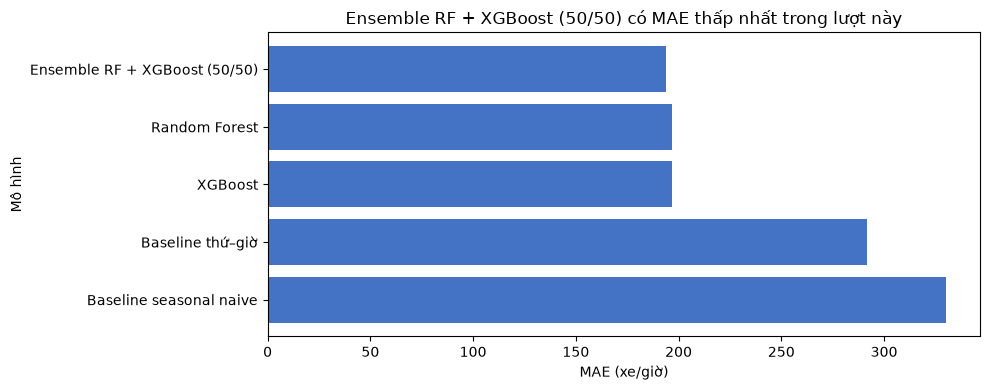

Đọc biểu đồ này như sau: thanh ngắn hơn tương ứng sai số tuyệt đối trung bình thấp hơn. Mọi thanh dùng cùng giờ chấm.

Trên cùng 6,050 giờ validation, Ensemble RF + XGBoost (50/50) đạt MAE thấp nhất 193.810 xe/giờ. RF đạt 196.775; XGBoost đạt 197.031 xe/giờ. Đây là đối chiếu bổ sung trên validation đã được xem trước; cần giữ test cho đánh giá cuối.

In [7]:
fig, ax = plt.subplots(figsize=(10,4))
ax.barh(metrics.model, metrics.MAE, color='#4472C4')
ax.invert_yaxis()
ax.set_xlabel('MAE (xe/giờ)')
ax.set_ylabel('Mô hình')
best = metrics.iloc[0]
ax.set_title(f'{best["model"]} có MAE thấp nhất trong lượt này')
fig.tight_layout()
fig.savefig(output_dir/'validation_mae.png', dpi=160, bbox_inches='tight')
plt.show()
comment = (f'Trên cùng {len(score):,} giờ validation, {best["model"]} đạt MAE thấp nhất {best["MAE"]:.3f} xe/giờ. '
           f'RF đạt {metrics.set_index("model").loc["Random Forest","MAE"]:.3f}; XGBoost đạt {metrics.set_index("model").loc["XGBoost","MAE"]:.3f} xe/giờ. '
           'Đây là đối chiếu bổ sung trên validation đã được xem trước; cần giữ test cho đánh giá cuối.')
display(Markdown('Đọc biểu đồ này như sau: thanh ngắn hơn tương ứng sai số tuyệt đối trung bình thấp hơn. Mọi thanh dùng cùng giờ chấm.\n\n'+comment))

## 8. Xuất bằng chứng
Lưu điểm, dự đoán từng timestamp, mốc chia, thống kê điền thiếu và cấu hình thực tế. Hash ma trận và cohort giúp xác nhận hai thí nghiệm dùng đúng cùng dữ liệu. Nhật ký Excel được cập nhật từ các file kết quả đã chạy, không chép con số từ ảnh Claude. Không ghi mô hình vào pipeline chính và không sửa kết quả tuning cũ.

In [8]:
prediction_table = pd.DataFrame({'date_time':score.date_time.to_numpy(),'y_true':y_validation,**predictions})
metrics.to_csv(output_dir/'validation_metrics.csv',index=False)
prediction_table.to_csv(output_dir/'validation_predictions.csv',index=False)
split_manifest.to_csv(output_dir/'split_manifest.csv',index=False)
source_hashes = {str(p.relative_to(project_root)):hashlib.sha256(p.read_bytes()).hexdigest() for p in [project_root/'src/model.py',project_root/'src/features.py',project_root/'src/feature_experiments.py',project_root/'src/preprocessing.py']}
run_config = {'experiment':EXPERIMENT_ID,'config':'C30','features':list(CONFIG_C),'seed':42,
    'parameter_source':PARAMETER_SOURCE,'explicit_params':MODEL_PARAMS,'effective_params':fitted_params,
    'tuning_protocol_hash_snapshot':TUNING_PROTOCOL_HASH,'n_train':len(fit),'n_validation':len(score),
    'split':split_manifest.to_dict('records'),'preprocessing':fill_statistics,
    'source_hashes':source_hashes,'input_prefix_hash':fe.frame_hash(hourly),
    'train_cohort_hash':fe.frame_hash(fit[['date_time','traffic_volume']]),
    'validation_cohort_hash':fe.frame_hash(score[['date_time','traffic_volume']]),
    'versions':{'python':platform.python_version(),'numpy':np.__version__,'pandas':pd.__version__,'sklearn':sklearn.__version__,'xgboost':xgboost.__version__},
    'fit_seconds':fit_seconds,'ensemble_weights':{'Random Forest':0.5,'XGBoost':0.5},
    'scenario':'Sequential hourly validation using only observed past history; same-hour weather assumed available',
    'validation_previously_seen':True,'test_evaluated':False}
# XGBoost có mặc định NaN; chuyển thành chuỗi để JSON không chứa số NaN không hợp lệ.
config_text = json.dumps(run_config,ensure_ascii=False,indent=2,default=str)
config_text = config_text.replace(': NaN', ': "NaN (library default)"')
(output_dir/'run_config.json').write_text(config_text,encoding='utf-8')
(output_dir/'assessment.md').write_text(comment+'\n\nNguồn tham số: '+PARAMETER_SOURCE,encoding='utf-8')
print('Đã lưu kết quả tại', output_dir.relative_to(project_root))

Đã lưu kết quả tại experiments\20-11-2026_Huy_C30_Params1\outputs
